In [2]:
from backend.utils.gmsh_function import *
from backend.utils.file_path import *

from backend.antenna_simulation.Nice_Cube.nice_cube_gmsh import create_nice_cube_geometry

from backend.src.radiation_algorithm.radiation_algorithm import *

from backend.cma.cma_frequency_sweep import cma_frequency_sweep
from backend.cma.modal_visualizer import ModalVisualizer

from backend.cma.cma_algorithm import cma_algorithm
from backend.cma.modal_farfield import compute_modal_farfield

In [3]:
name = "Nice_Cube"
path = setup_save_file_paths(name)

In [4]:
cm = 1e-2 # 1 cm
mm = 1e-3 # 1 mm

C = 10 * cm # Length of the cube's edge

initial_mesh_size = 40 * mm

space_btw_cubesat_and_solar_panel = 5 * mm # 1 cm = 10 mm

length_of_connection_between_cubesat_and_solar_panel = 10 * mm # 1.5 cm = 15 mm

In [7]:
# Coding the Nice CubeSat geometry
gmsh.initialize()

gmsh.model.add("CubeSat")

setup_performance_config()

create_nice_cube_geometry(C, space_btw_cubesat_and_solar_panel, length_of_connection_between_cubesat_and_solar_panel)
# create_nice_cube_geometry_v2(C, space_btw_cubesat_and_solar_panel, length_of_connection_between_cubesat_and_solar_panel)

generate_and_save_mesh(path, initial_mesh_size)

gmsh.fltk.run()

gmsh.finalize()

[PERFORMANCE] Gmsh configured to utilize 16 threads.
Geometry file saved in data/gmsh_files/Nice_Cube.brep successfully
--- Starting Mesh Optimization (Dim: 2) ---
--- Optimization Complete ---
Mesh file saved in data/gmsh_files/Nice_Cube.msh successfully


In [5]:
n_modes_cma = 4

In [6]:
# 1. Eigenvalues over a frequency range

freq_start_cma = 100e6
freq_stop_cma = 500e6

sweep_data = cma_frequency_sweep(path, freq_start_cma, freq_stop_cma, n_points=7, n_modes=n_modes_cma)

Mesh ready: 309 points, 530 triangles, 757 edges -- regenerated from data/gmsh_files/Nice_Cube.msh

Assembling Z(f) for 7 frequencies (757x757 edges) on GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) -- geometry reused across the whole sweep...
[calculate_z_matrice_sweep] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (757x757 edges, 7 frequencies).
Z(f) assembly done in 21.6 s (3.090 s/frequency amortised)

Step 1/7 |   100.00 MHz | lambda: -13.906, -14.152, -29.970, 198.320
Step 2/7 |   166.67 MHz | lambda: -1.208, -1.211, -3.521, -26.019
Step 3/7 |   233.33 MHz | lambda: 0.245, 0.609, 0.640, 1.219
Step 4/7 |   300.00 MHz | lambda: 1.040, 1.048, 1.069, 3.488
Step 5/7 |   366.67 MHz | lambda: 1.144, 1.144, 1.258, 3.295
Step 6/7 |   433.33 MHz | lambda: 1.116, 1.119, 1.305, 2.945
Step 7/7 |   500.00 MHz | lambda: -1.035, 1.038, 1.038, 1.424

Mode tracking: 4 modes over 7 frequencies (metric='R', correction='none')
  accepted correlation: min 0.0004, median

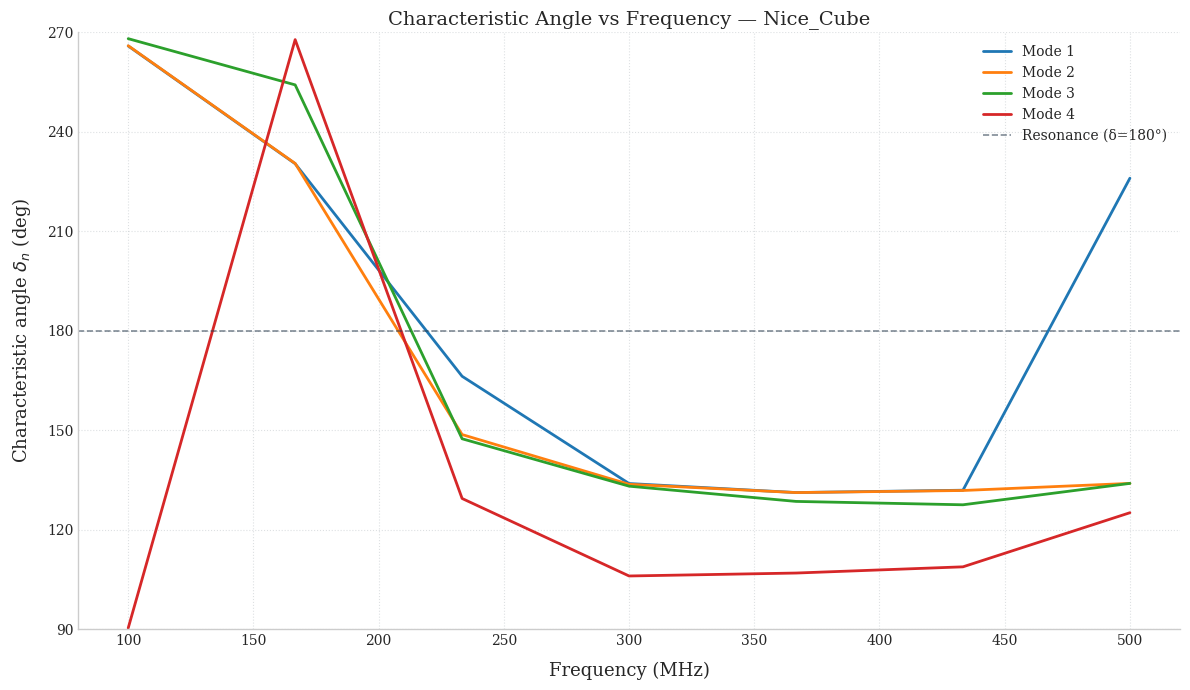

In [7]:
# 2. Characteristic angle delta_n = 180 - atan(lambda_n), for the first 6 modes.
#    Read this one first: delta stays inside (90, 270) deg so every mode is visible
#    at the same scale, whereas lambda spans ~1e5 here and would flatten all but one
#    curve. A mode resonates where it crosses 180 deg; the steeper the crossing, the
#    narrower its band (higher Q).
ModalVisualizer.plot_characteristic_angle_vs_frequency(sweep_data, n_modes_to_plot=n_modes_cma, antenna_name=path.name)

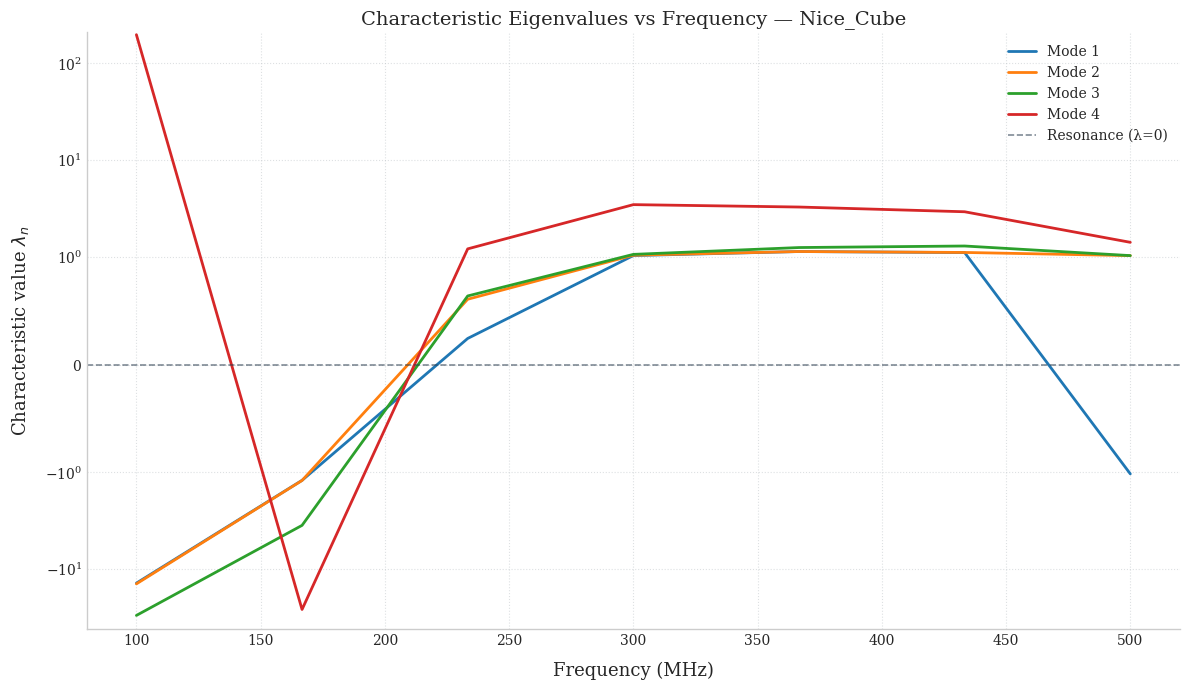

In [8]:
# 3. Raw eigenvalues lambda_n for the first 6 modes.
#    y axis is symlog by default: linear within +/-1 so the zero crossings (the
#    resonances) stay undistorted, logarithmic beyond so the far-from-resonance
#    modes reaching ~1e5 remain readable. Pass yscale='linear' for the raw view.
ModalVisualizer.plot_eigenvalues_vs_frequency(sweep_data, n_modes_to_plot=n_modes_cma, antenna_name=path.name)

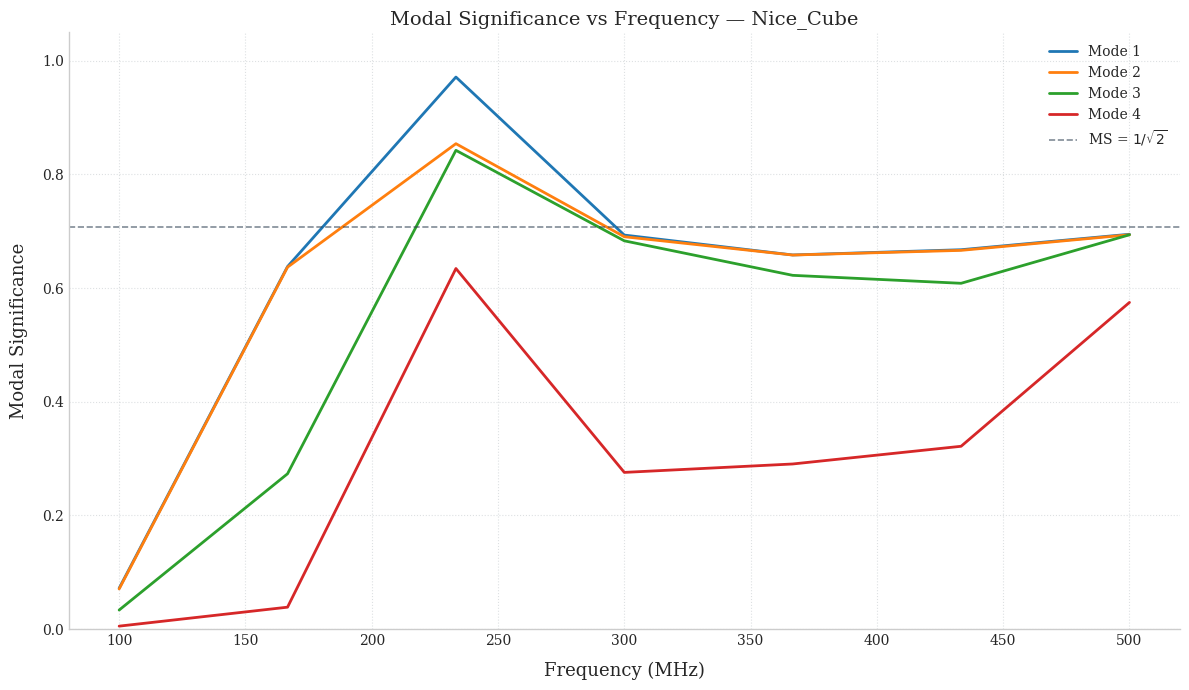

In [9]:
# 4. Modal Significance for the first 6 modes
ModalVisualizer.plot_modal_significance(sweep_data, n_modes_to_plot=n_modes_cma, antenna_name=path.name)

In [10]:
# 5. Characteristic currents of the first 6 modes, at the design frequency.
#    show_current_arrows=True (default) overlays black arrows along the modal
#    current; save_image=True writes cma_mode<n>_current_<name>.pdf.
frequency = 436.5e6
modal_data = cma_algorithm(path, frequency=frequency, n_modes=n_modes_cma,
                           show=True, save_image=False, show_current_arrows=True)

[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (757x757 edges).
CMA report written to: data/antennas_cma\Nice_Cube_cma_report.md
CMA: 4 modes computed at f = 0.4365 GHz
  lambda range: [1.1114, 2.9332]


In [11]:
# 6. Far-field pattern of the first 6 modes, at the same design frequency.
#    save_image=True writes cma_mode<n>_farfield_<name>.pdf into data/fig_image/
#    (efield2's renderer forces an empty title, so the mode is identified by the
#    filename rather than inside the image).
_, triangles, edges, _vecteurs_rho = DataManager_rwg2.load_data(path.mat_mesh2)
freq_cma, _omega, _mu, _epsilon, light_speed_c, eta, _Z = DataManager_rwg3.load_data(path.mat_impedance)

for n in range(n_modes_cma):
    J_n = modal_data.eigenvectors[:, n]
    sphere_points, sphere_triangles, gain_db, directivity_max = compute_modal_farfield(
        triangles, edges, J_n, freq_cma, light_speed_c, eta)
    print(f"Mode {n + 1} (lambda = {modal_data.eigenvalues[n]:.4f}): "
          f"peak directivity = {10 * np.log10(directivity_max):.2f} dBi")
    fig = ModalVisualizer.plot_mode_farfield(sphere_points, sphere_triangles, gain_db,
                                              mode_index=n, eigenvalue=modal_data.eigenvalues[n],
                                              save_image=False, antenna_name=path.name)
    fig.show()

Hollow sphere loaded: 5150 points, 10296 triangles.
Mode 1 (lambda = 1.1114): peak directivity = 3.67 dBi


Hollow sphere loaded: 5150 points, 10296 triangles.
Mode 2 (lambda = 1.1167): peak directivity = 3.61 dBi


Hollow sphere loaded: 5150 points, 10296 triangles.
Mode 3 (lambda = 1.3075): peak directivity = 1.74 dBi


Hollow sphere loaded: 5150 points, 10296 triangles.
Mode 4 (lambda = 2.9332): peak directivity = 3.65 dBi
